# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: I predict that a woman or child traveling in first class would have the highest chance of surviving the Titanic. From what I know about the Titanic, women and children were given priority when getting onto lifeboats and first-class passengers may have had better access to them. I think a man traveling in third class would have the lowest chance of surviving because he may have had a harder time reaching the lifeboats. I also think traveling with family could make a difference but I'm not sure if it would help or hurt their chances.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt



In [2]:

titanic_df = pd.read_csv("data/titanic_passengers.csv")


In [3]:

titanic_df.head()



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:

titanic_df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:

titanic_df.isna().sum()



PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: Each row represents one passenger from the Titanic dataset. The target feature is Survived because we are trying to compare which groups of passengers had a higher chance of surviving. A value of 0 means the passenger did not survive and a value of 1 means the passenger survived. The dataset has 891 passengers but it doesn't include everyone who was on the Titanic.


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| PassengerId | Identifier | int64 | 0 |
| Name | Identifier | object | 0 |
| Survived | Categorical (0 = No, 1 = Yes) | int64 | 0 |
| Pclass | Categorical (1st, 2nd, 3rd class) | int64 | 0 |
| Sex | Categorical | object | 0 |
| Age | Quantitative (years) | float64 | 177 |
| Parch | Quantitative count (parents/children aboard) | int64 | 0 |
| SibSp | Quantitative count (siblings/spouse aboard) | int64 | 0 |
| Embarked | Categorical (C, Q, S) | object | 2 |

## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
Children	Under 13 years
Teens	13–17 years
Adults	18–59 years
Older Adults	60 years and older
Unknown	Age not recorded


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: I chose these age groups because I want to see if children and teenagers had different survival rates compared to adults and older passengers. From what I know about the Titanic, children may have been given priority when getting onto lifeboats. There are also 177 passengers with missing ages so I will put them in an Unknown group instead of guessing their ages or removing them.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:

titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 13, "age_group"] = "Children"
titanic_df.loc[
    (titanic_df["Age"] >= 13) & (titanic_df["Age"] < 18),
    "age_group"
] = "Teens"

titanic_df.loc[
    (titanic_df["Age"] >= 18) & (titanic_df["Age"] < 60),
    "age_group"
] = "Adults"

titanic_df.loc[titanic_df["Age"] >= 60, "age_group"] = "Older Adults"

titanic_df["age_group"].value_counts()


age_group
Adults          575
Unknown         177
Children         69
Teens            44
Older Adults     26
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: The results show that older adults only have 26 passengers and teenagers have 44 compared to 575 adults. Those groups are smaller so their survival percentage could chage with lower amount of passengers. I thought about combining some groups but I decided to keep them separate because I want to see if teenagers and older adults had different survival rates. I will keep the 177 unknown ages in their own group instead of guessing.


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [8]:

print("Parents/Children Aboard:")
print(titanic_df["Parch"].value_counts().sort_index())

print("\nSiblings/Spouse Aboard:")
print(titanic_df["SibSp"].value_counts().sort_index())


titanic_df["parch_group"] = titanic_df["Parch"].apply(
    lambda x: "None" if x == 0 else "One" if x == 1 else "Two or More"
)

titanic_df["sibsp_group"] = titanic_df["SibSp"].apply(
    lambda x: "None" if x == 0 else "One" if x == 1 else "Two or More"
)

print("Parch Groups:")
print(titanic_df["parch_group"].value_counts())

print("\nSibSp Groups:")
print(titanic_df["sibsp_group"].value_counts())




Parents/Children Aboard:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

Siblings/Spouse Aboard:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64
Parch Groups:
parch_group
None           678
One            118
Two or More     95
Name: count, dtype: int64

SibSp Groups:
sibsp_group
None           608
One            209
Two or More     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: I decided to use three groups for both Parch and SibSp which are none, one, and two or more. Looking at the data I noticed that most passengers had no parents or children aboard with 678 passengers and 608 had no siblings or spouse aboard. Some of the higher numbers only had a few passengers so I combined them into one group to make the comparison easier. I won't remove any passengers from these comparisons. For the two passengers with missing embarkation ports I will leave them out of that specific comparison. The survival percentages will be calculated using the total number of passengers in each group instead of all 891 passengers.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [9]:

age_counts = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"]
)

age_counts


Survived,0,1
age_group,,
Adults,353,222
Children,29,40
Older Adults,19,7
Teens,23,21
Unknown,125,52


In [10]:

age_survival = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

age_survival[1]



age_group
Adults          38.608696
Children        57.971014
Older Adults    26.923077
Teens           47.727273
Unknown         29.378531
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [11]:

age_joint = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="all"
) * 100

age_joint.round(2)


Survived,0,1
age_group,,
Adults,39.62,24.92
Children,3.25,4.49
Older Adults,2.13,0.79
Teens,2.58,2.36
Unknown,14.03,5.84


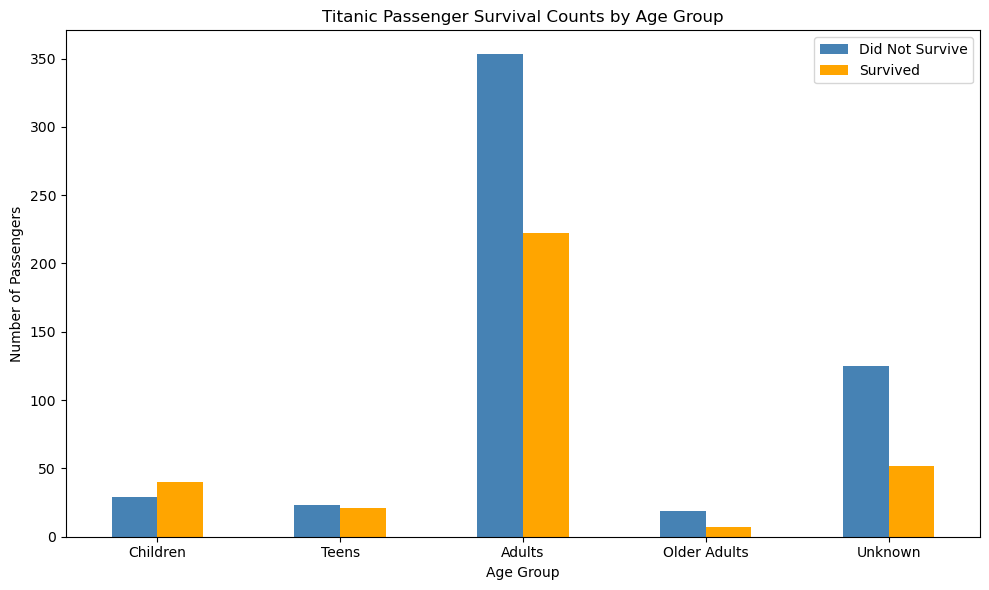

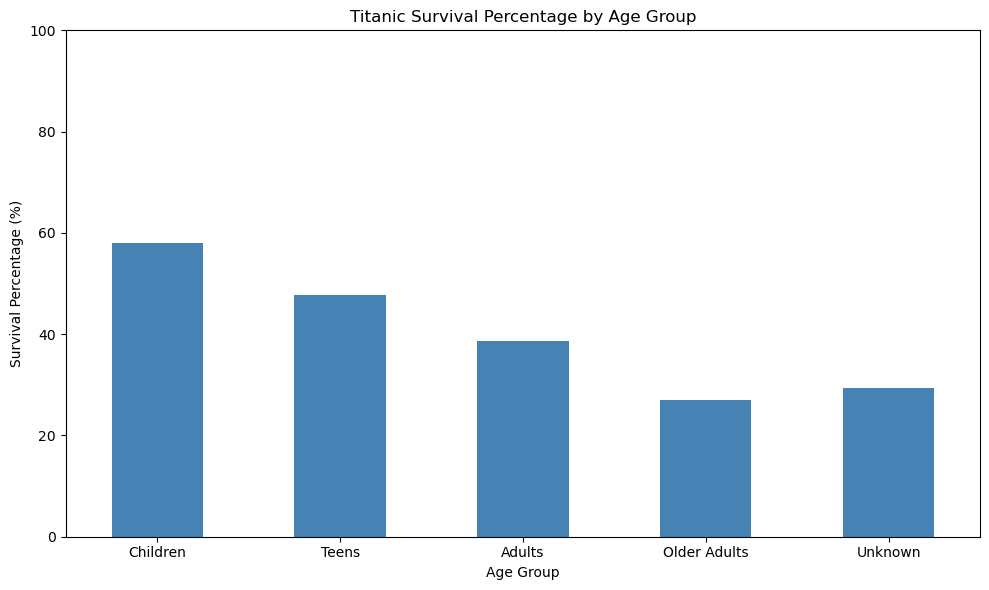

In [13]:

age_order = [
    "Children", "Teens", "Adults",
    "Older Adults", "Unknown"
]

age_counts.loc[age_order].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "orange"]
)

plt.title("Titanic Passenger Survival Counts by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()


age_survival.loc[age_order, 1].plot(
    kind="bar",
    figsize=(10, 6),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [14]:

sex_counts = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"]
)

sex_counts



Survived,0,1
Sex,,
female,81,233
male,468,109


In [15]:

sex_survival = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sex_survival[1]



Sex
female    74.203822
male      18.890815
Name: 1, dtype: float64

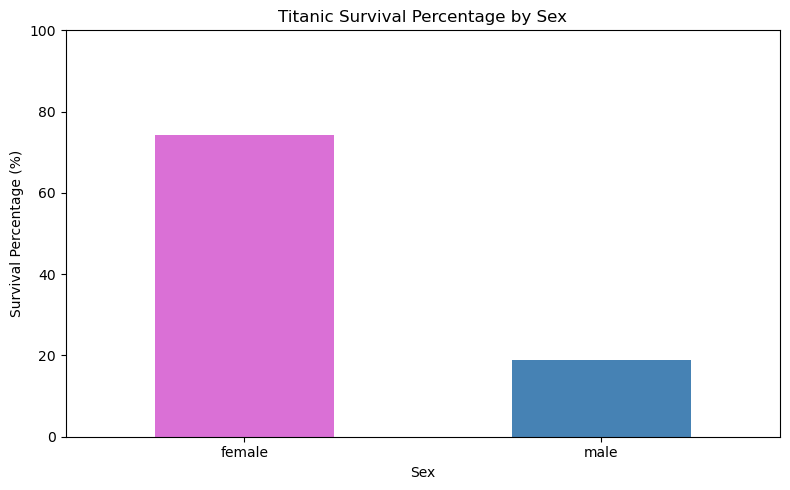

In [16]:

sex_survival.loc[["female", "male"], 1].plot(
    kind="bar",
    figsize=(8, 5),
    color=["orchid", "steelblue"]
)

plt.title("Titanic Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [17]:

class_counts = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"]
)

class_counts


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [18]:

class_survival = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"],
    normalize="index"
) * 100

class_survival[1].round(2)



Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64

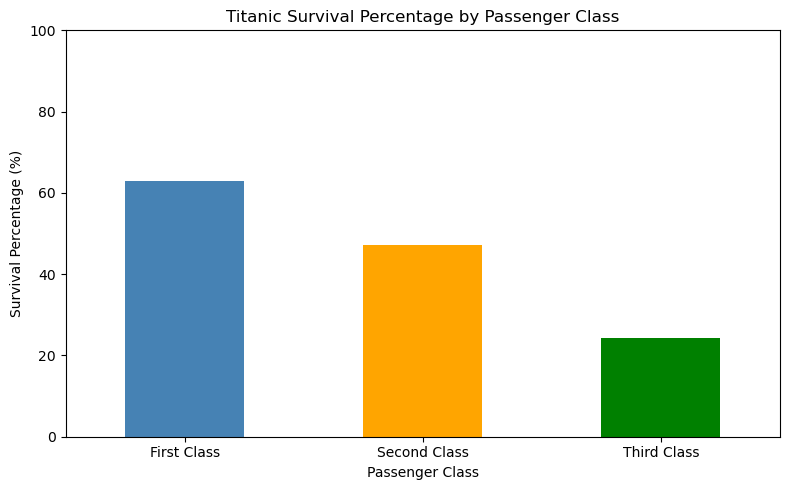

In [19]:

class_survival.loc[[1, 2, 3], 1].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange", "green"]
)

plt.title("Titanic Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(
    ticks=[0, 1, 2],
    labels=["First Class", "Second Class", "Third Class"],
    rotation=0
)
plt.tight_layout()
plt.show()



### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [20]:

parch_counts = pd.crosstab(
    titanic_df["parch_group"],
    titanic_df["Survived"]
)

parch_counts.loc[["None", "One", "Two or More"]]



Survived,0,1
parch_group,,
None,445,233
One,53,65
Two or More,51,44


In [21]:

parch_survival = pd.crosstab(
    titanic_df["parch_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

parch_survival.loc[["None", "One", "Two or More"], 1].round(2)



parch_group
None           34.37
One            55.08
Two or More    46.32
Name: 1, dtype: float64

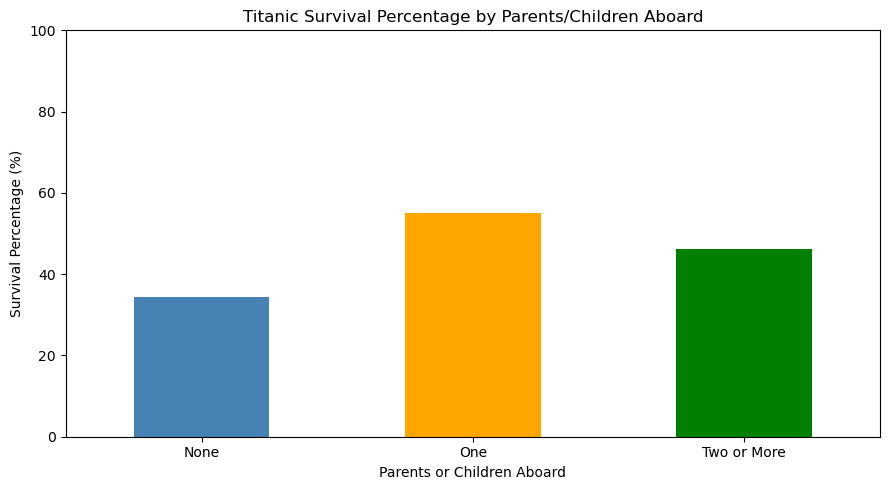

In [22]:

parch_survival.loc[
    ["None", "One", "Two or More"], 1
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange", "green"]
)

plt.title("Titanic Survival Percentage by Parents/Children Aboard")
plt.xlabel("Parents or Children Aboard")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [23]:

sibsp_counts = pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"]
)

sibsp_counts.loc[["None", "One", "Two or More"]]


Survived,0,1
sibsp_group,,
None,398,210
One,97,112
Two or More,54,20


In [24]:

sibsp_survival = pd.crosstab(
    titanic_df["sibsp_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sibsp_survival.loc[["None", "One", "Two or More"], 1].round(2)



sibsp_group
None           34.54
One            53.59
Two or More    27.03
Name: 1, dtype: float64

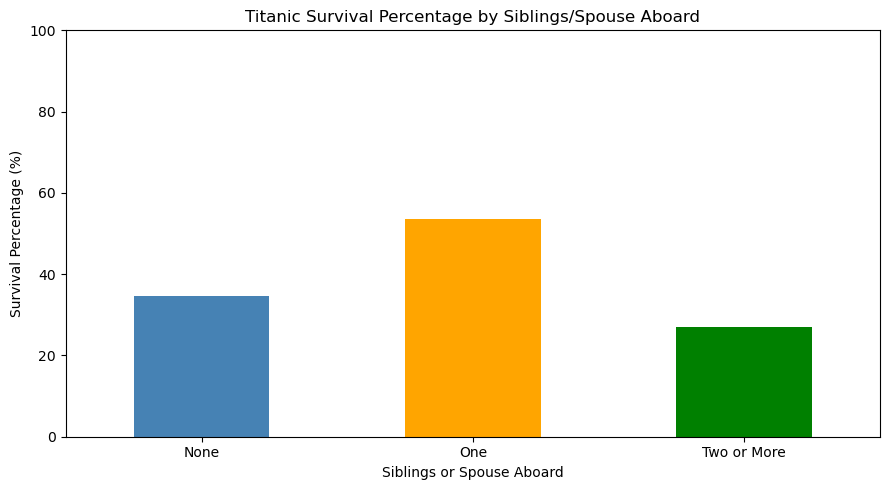

In [25]:

sibsp_survival.loc[
    ["None", "One", "Two or More"], 1
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange", "green"]
)

plt.title("Titanic Survival Percentage by Siblings/Spouse Aboard")
plt.xlabel("Siblings or Spouse Aboard")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [26]:

embarked_counts = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"]
)

embarked_counts.loc[["C", "Q", "S"]]



Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [27]:

embarked_survival = pd.crosstab(
    titanic_df["Embarked"],
    titanic_df["Survived"],
    normalize="index"
) * 100

embarked_survival.loc[["C", "Q", "S"], 1].round(2)



Embarked
C    55.36
Q    38.96
S    33.70
Name: 1, dtype: float64

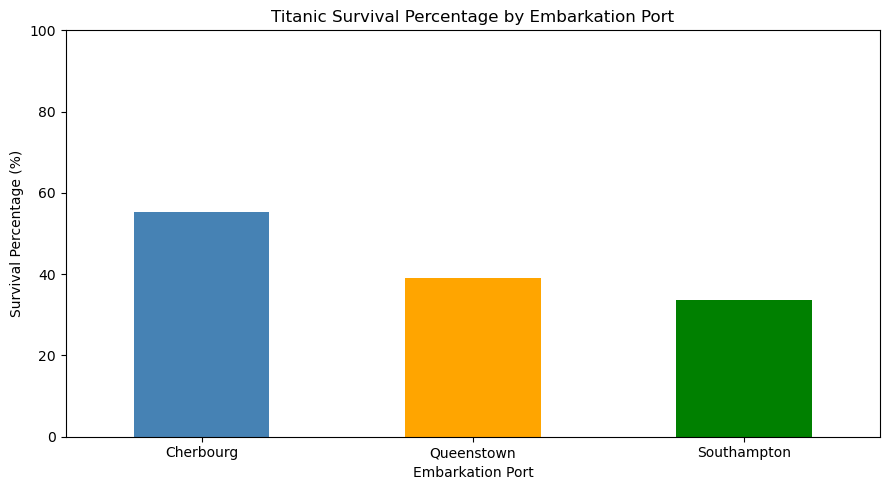

In [28]:

embarked_survival.loc[
    ["C", "Q", "S"], 1
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange", "green"]
)

plt.title("Titanic Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Cherbourg", "Queenstown", "Southampton"],
    rotation=0
)
plt.tight_layout()
plt.show()



### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
Sex	Female: 74.2% (233 of 314)	Male: 18.9% (109 of 577)
Age groups	Children: 57.97% (40 of 69)	Older Adults: 26.92% (7 of 26)
Passenger class	First Class: 62.96% (136 of 216)	Third Class: 24.24% (119 of 491)
Parents or children aboard	One: 55.08% (65 of 118)	None: 34.37% (233 of 678)
Siblings or spouse aboard	One: 53.59% (112 of 209)	Two or More: 27.03% (20 of 74)
Embarkation port	Cherbourg: 55.36% (93 of 168)	Southampton: 33.70% (217 of 644)


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: Looking at the age results I noticed that 40 children survived out of the 891 passengers which is about 4.49% of the entire dataset. That is the joint percentage because it uses all 891 passengers. The conditional percentage was 57.97% because 40 out of the 69 children survived. I think the conditional percentage is more useful because it shows the chance of surviving within each age group instead of comparing everyone together. The count graph shows how many survived but the percentage graph makes it easier to compare the groups.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [29]:

age_check = titanic_df.groupby("age_group")["Age"].agg(
    ["count", "min", "max"]
)

age_check.loc[
    ["Children", "Teens", "Adults", "Older Adults", "Unknown"]
]



,count,min,max
age_group,,,
Children,69,0.42,12.0
Teens,44,13.00,17.0
Adults,575,18.00,59.0
Older Adults,26,60.00,80.0
Unknown,0,NaN,NaN


In [30]:

print("Parch category check:")
print(pd.crosstab(
    titanic_df["Parch"],
    titanic_df["parch_group"]
))

print("\nSibSp category check:")
print(pd.crosstab(
    titanic_df["SibSp"],
    titanic_df["sibsp_group"]
))



Parch category check:
parch_group  None  One  Two or More
Parch                              
0             678    0            0
1               0  118            0
2               0    0           80
3               0    0            5
4               0    0            4
5               0    0            5
6               0    0            1

SibSp category check:
sibsp_group  None  One  Two or More
SibSp                              
0             608    0            0
1               0  209            0
2               0    0           28
3               0    0           16
4               0    0           18
5               0    0            5
8               0    0            7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: I checked the age groups to make sure the passengers were placed in the correct categories. I also checked the Parch and SibSp groups to make sure passengers with zero family members were placed under None, one under One, and two or more together. I checked the survival percentages using the total passengers in each group instead of only the survivors. The older adult group only had 26 passengers and teenagers had 44 so those percentages could change more easily compared to the larger groups. I also kept the 177 passengers with unknown ages separate instead of guessing their ages.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Children: 57.97% survived (40 of 69 passengers) | Older Adults: 26.92% survived (7 of 26 passengers) |
| Passenger class | First Class: 62.96% survived (136 of 216 passengers) | Third Class: 24.24% survived (119 of 491 passengers) |
| Parents or children aboard | One: 55.08% survived (65 of 118 passengers) | None: 34.37% survived (233 of 678 passengers) |
| Siblings or spouse aboard | One: 53.59% survived (112 of 209 passengers) | Two or More: 27.03% survived (20 of 74 passengers) |
| Embarkation port | Cherbourg: 55.36% survived (93 of 168 passengers) | Southampton: 33.70% survived (217 of 644 passengers) |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: For my most likely to survive character I would choose a young girl traveling in first class who boarded in Cherbourg. I chose her because looking at the data females, children, and first class passengers had higher survival rates. She would also be traveling with one parent and one sibling because those groups had higher survival rates too.

For my least likely to survive character I would choose an older man traveling in third class who boarded in Southampton. He would have no parents or children with him but would have two or more siblings or a spouse aboard. Looking at the results these groups had some of the lowest survival rates.

One thing I noticed is that just because these groups had higher or lower survival rates doesn't mean putting them together guarantees someone would survive or not. Some of these combinations might not even be in the dataset so I would need to check that first.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [31]:

most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female") &
    (titanic_df["age_group"] == "Children") &
    (titanic_df["Pclass"] == 1) &
    (titanic_df["parch_group"] == "One") &
    (titanic_df["sibsp_group"] == "One") &
    (titanic_df["Embarked"] == "C")
].copy()

most_likely_df[
    ["PassengerId", "Name", "Sex", "Age", "Pclass",
     "Parch", "SibSp", "Embarked", "Survived"]
]



,PassengerId,Name,Sex,Age,Pclass,Parch,SibSp,Embarked,Survived


In [32]:

least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Older Adults") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["parch_group"] == "None") &
    (titanic_df["sibsp_group"] == "Two or More") &
    (titanic_df["Embarked"] == "S")
].copy()

least_likely_df[
    ["PassengerId", "Name", "Sex", "Age", "Pclass",
     "Parch", "SibSp", "Embarked", "Survived"]
]



,PassengerId,Name,Sex,Age,Pclass,Parch,SibSp,Embarked,Survived


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: Looking at the results I noticed that neither of my profiles matched any passengers when I used all six characteristics together. This means that even though those groups had the highest and lowest survival rates individually there wasn't anyone in the dataset who matched everything. I will need to adjust some of the characteristics to find actual passengers while keeping the profiles as close as possible to my original predictions.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: For my most likely to survive character I chose Margaretta Corning Spedden, Passenger ID 320. I matched her name, passenger class, and where she boarded with her Encyclopedia Titanica biography. She was traveling in first class with her husband and son and survived the Titanic. Something interesting I found was that she enjoyed photography and wrote a story about the Titanic from the perspective of her son's toy bear. The story was later published as Polar, the Titanic Bear. The dataset lists her age as 40 but her biography says she was 39.

Source: https://www.encyclopedia-titanica.org/titanic-survivor/margaretta-corning-spedden.html


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: For my least likely to survive character I chose Johan Hansen Nysveen, Passenger ID 327. His name is listed as Johannes Hansen Nysveen in Encyclopedia Titanica but his age, passenger class, and where he boarded match the dataset. He was a 61 year old man traveling in third class and did not survive. Something interesting I found was that he was a farmer from Norway who was returning to North Dakota to give his share of a farm to one of his sons. He wasn't originally planning to travel on the Titanic.

Source: https://www.encyclopedia-titanica.org/titanic-victim/johan-hansen-nysveen.html


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [35]:

# Find passengers closest to the most likely profile
most_conditions = [
    titanic_df["Sex"] == "female",
    titanic_df["age_group"] == "Children",
    titanic_df["Pclass"] == 1,
    titanic_df["parch_group"] == "One",
    titanic_df["sibsp_group"] == "One",
    titanic_df["Embarked"] == "C"
]

most_scores = sum(condition.astype(int) for condition in most_conditions)

most_matches = titanic_df.copy()
most_matches["Matching_Features"] = most_scores

most_matches.sort_values(
    "Matching_Features", ascending=False
)[
    ["PassengerId", "Name", "Sex", "Age",
     "Pclass", "Parch", "SibSp", "Embarked",
     "Matching_Features"]
].head(10)



least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Older Adults") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["parch_group"] == "None") &
    (titanic_df["sibsp_group"] == "None") &
    (titanic_df["Embarked"] == "S")
].copy()

least_likely_df[
    ["PassengerId", "Name", "Sex", "Age",
     "Pclass", "Parch", "SibSp", "Embarked", "Survived"]
]




,PassengerId,Name,Sex,Age,Pclass,Parch,SibSp,Embarked,Survived
326,327,"Nysveen, Mr. Johan Hansen",male,61.0,3,0,0,S,0
851,852,"Svensson, Mr. Johan",male,74.0,3,0,0,S,0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: Looking at the results both of the older men I found for my least likely to survive profile did not survive. Johan Hansen Nysveen was 61 and Johan Svensson was 74. Both were third class passengers who boarded in Southampton. This matches what I predicted for that profile. However just because these two passengers did not survive doesn't mean everyone with the same characteristics would have the same outcome. I still need to compare my most likely to survive character and check the historical records.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: For my Titanic movie I would recommend Margaretta Spedden as the most likely to survive character and Johan Hansen Nysveen as the least likely. Looking at the data 74.2% of women survived compared to only 18.9% of men. First class passengers had a survival rate of 62.96% compared to 24.24% for third class. Passengers who boarded in Cherbourg also had a higher survival rate than those who boarded in Southampton.

Margaretta was a first class passenger who survived. I found out that she enjoyed photography and even wrote a story about the Titanic using her son's toy bear. Johan was a third class passenger who did not survive. He was a farmer traveling back to North Dakota to give part of his farm to his son.

My original predictions were mostly right but I had to change one characteristic for each person because nobody matched all six. I think these two characters would be good for the movie because they experienced the same disaster but had very different backgrounds and outcomes. The data supports my choices but it doesn't mean their characteristics guaranteed what happened to them.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: I wouldn't say that someone was guaranteed to survive or die just because they matched certain characteristics. The data shows that women, children, and first class passengers had higher survival rates but that doesn't mean those things alone caused them to survive. There were also 177 passengers with missing ages and some groups like older adults only had 26 passengers. Another issue is that I had to change my original profiles because nobody matched all six characteristics. The dataset only has 891 passengers and doesn't include everyone on the Titanic so I wouldn't use these results to predict exactly what would happen to one person.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to help me understand the assignment, write some of the Python code, and explain the results. One suggestion I checked was using six conditions to find passengers who matched my character profiles. When I ran the code neither profile returned any passengers. I then checked which passengers matched five out of six characteristics and changed one category in my least likely to survive profile. I accepted this approach because I could verify the results using the original dataset instead of just guessing which passengers fit.


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
